# 04 · Disparadores de reentrenamiento: KS + Bonferroni y umbral bootstrap 2σ

**Responsabilidad:** explicar y reproducir las dos alarmas que usa el grupo B.

1. **Deriva de datos:** ¿las features de la ventana se distribuyen distinto que las del entrenamiento? Se usa Kolmogorov–Smirnov por feature con corrección de Bonferroni ([9] p. 4 y 6).
2. **Caída de desempeño:** ¿el F1 de la ventana cayó más de lo que explicaría el azar? La regla es `F1_ventana < F1_ref − 2σ`, con σ estimada por bootstrap ([6] p. 3 y 6, [25]).

B reentrena si se cumple **(1) o (2)**. Hacen falta las dos porque [13] muestra que el desempeño puede caer sin deriva visible en los datos.

In [1]:
import os, pathlib, warnings
warnings.filterwarnings("ignore")
root = pathlib.Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)  # todas las rutas del proyecto son relativas a la raíz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from msft_mlops.config import load_config
from msft_mlops.data import load_raw
from msft_mlops.features import build_dataset

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
# Paleta validada (dataviz): A azul, B naranja, C aqua; baselines y neutros en gris.
COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
MARKER = {"A": "o", "B": "s", "C": "^"}
GRIS = "#8a8a85"

cfg = load_config()
f = cfg["features"]
FEAT_KW = dict(n_lags=f["n_lags"], ma_windows=tuple(f["ma_windows"]), vol_ma_window=f["vol_ma_window"])
raw = load_raw(cfg)              # falla si el SHA-256 no coincide con config/experiment.toml
ds = build_dataset(raw, **FEAT_KW)
FEATS = [c for c in ds.columns if c != "y"]
print(f"raw: {len(raw)} filas | dataset modelable: {len(ds)} filas, {len(FEATS)} features")

raw: 1254 filas | dataset modelable: 1234 filas, 9 features


In [2]:
from scipy import stats
from msft_mlops.windows import split_2021, test_windows
from msft_mlops.drift import detect_drift
from msft_mlops.models import fit_model, predict
from msft_mlops.metrics import f1_value
from msft_mlops.threshold import f1_reference_and_sigma
from msft_mlops.policies import make_policies
_, _, initial_df = split_2021(ds, cfg["split"])
w = test_windows(ds, cfg["split"])[0]
ref, cur = initial_df[FEATS], w.data[FEATS]
print(f"Ejemplo: referencia = entrenamiento del modelo vigente ({len(ref)} días de 2021) | ventana {w.window_id} ({len(cur)} días)")

Ejemplo: referencia = entrenamiento del modelo vigente (211 días de 2021) | ventana 2022-H1 (124 días)


## 1. Kolmogorov–Smirnov (KS)

KS compara dos muestras y pregunta si vienen de la misma distribución, sin suponer normalidad.
- Se dibuja la **distribución acumulada** de cada muestra (ECDF): para cada valor x, qué proporción de días tiene la feature ≤ x.
- **Estadístico D:** la distancia vertical máxima entre las dos curvas.
- **p-valor:** probabilidad de ver una D tan grande si no hubiera deriva. p chico indica deriva.

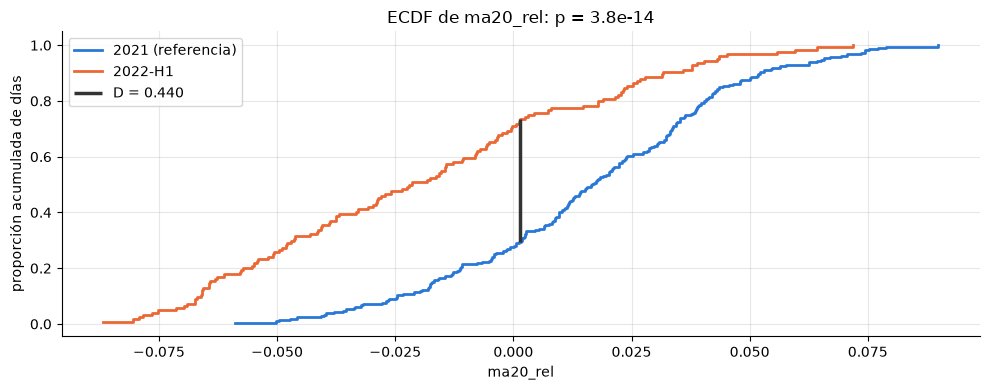

In [3]:
feat = "ma20_rel"
fig, ax = plt.subplots()
curvas = {}
for data, lab, c in [(ref[feat], "2021 (referencia)", COLOR["A"]), (cur[feat], w.window_id, COLOR["B"])]:
    x = np.sort(data); ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", label=lab, color=c); curvas[lab] = x
res = stats.ks_2samp(ref[feat], cur[feat])
grid_x = np.sort(np.concatenate(list(curvas.values())))
e1 = np.searchsorted(np.sort(ref[feat]), grid_x, side="right") / len(ref); e2 = np.searchsorted(np.sort(cur[feat]), grid_x, side="right") / len(cur)
k = np.argmax(np.abs(e1 - e2)); ax.vlines(grid_x[k], e1[k], e2[k], color="#333", lw=2.5, label=f"D = {res.statistic:.3f}")
ax.set_title(f"ECDF de {feat}: p = {res.pvalue:.2g}"); ax.legend(); ax.set_ylabel("proporción acumulada de días"); ax.set_xlabel(feat)
plt.tight_layout()

**Cómo leerlo:** la curva azul es 2021 y la naranja 2022-H1. El segmento negro marca la distancia máxima D entre ellas.

**Qué concluimos:** En 2022-H1 la curva naranja está desplazada a la izquierda: el precio pasó mucho más tiempo **por debajo** de su media de 20 días (mercado bajista). La distancia es tan grande que el p-valor es prácticamente 0: hay deriva clara.

## 2. Corrección de Bonferroni

Problema: se hacen 9 tests a la vez (uno por feature). Con α = 0,05 cada uno, la probabilidad de al menos una **falsa alarma** sería 1 − 0,95⁹ ≈ 37 %.

Bonferroni divide α entre el número de tests: hay deriva si `min(p) < 0,05 / 9 ≈ 0,0056`. Así el sistema completo mantiene una tasa de falsas alarmas de 5 % como máximo.

P(≥1 falsa alarma sin corregir) = 37.0%


,D,p_scipy,deriva
ret_0,0.259,4.068e-05,True
ret_1,0.246,1.153e-04,True
ret_2,0.242,1.673e-04,True
ret_3,0.234,3.095e-04,True
ret_4,0.225,5.606e-04,True
ma5_rel,0.293,2.020e-06,True
ma10_rel,0.347,7.217e-09,True
ma20_rel,0.440,3.781e-14,True
vol_rel,0.070,8.044e-01,False


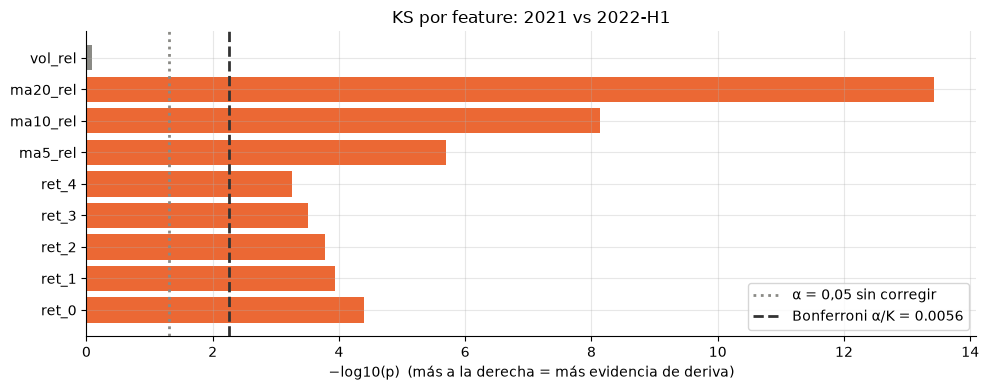

In [4]:
alpha, K = cfg["drift"]["alpha"], len(FEATS)
ks = pd.DataFrame({c: stats.ks_2samp(ref[c], cur[c]) for c in FEATS}, index=["D", "p_scipy"]).T
ks["deriva"] = ks.p_scipy < alpha / K
fig, ax = plt.subplots()
ax.barh(ks.index, -np.log10(ks.p_scipy.clip(lower=1e-16)), color=[COLOR["B"] if d else GRIS for d in ks.deriva])
ax.axvline(-np.log10(alpha), color=GRIS, ls=":", label="α = 0,05 sin corregir")
ax.axvline(-np.log10(alpha / K), color="#333", ls="--", label=f"Bonferroni α/K = {alpha/K:.4f}")
ax.set_xlabel("−log10(p)  (más a la derecha = más evidencia de deriva)"); ax.legend(); ax.set_title(f"KS por feature: 2021 vs {w.window_id}")
plt.tight_layout()
print(f"P(≥1 falsa alarma sin corregir) = {1 - (1 - alpha) ** K:.1%}")
ks

**Cómo leerlo:** cada barra es la evidencia de deriva de una feature (escala −log10 del p-valor: 2 equivale a p = 0,01 y 5 a p = 0,00001). Las barras naranjas cruzan la línea de Bonferroni.

**Qué concluimos:** En 2022-H1 derivan los rendimientos (volatilidad de 2022 frente a la calma de 2021) y las medias móviles. `vol_rel` no deriva. Basta que **una** feature cruce la línea para declarar deriva.

**Implementación real:** el pipeline calcula la deriva con Evidently (`detect_drift`). Comprobamos que da los mismos p-valores que scipy:

In [5]:
dr = detect_drift(ref, cur, alpha)
assert np.allclose(ks.p_scipy, pd.Series(dr.per_feature))
print(f"OK Evidently = scipy | deriva = {dr.drifted} (min p = {dr.min_p:.2g} < {dr.threshold:.4f})")

OK Evidently = scipy | deriva = True (min p = 3.8e-14 < 0.0056)


## 3. La deriva en todas las ventanas (resultados del grupo B)

window_id,2022-H1,2022-H2,2023-H1,2023-H2,2024-H1,2024-H2,2025-H1,2025-H2
min_p,3.781e-14,0.053,2.478e-07,0.003,0.005,0.004,2.710e-04,1.725e-04


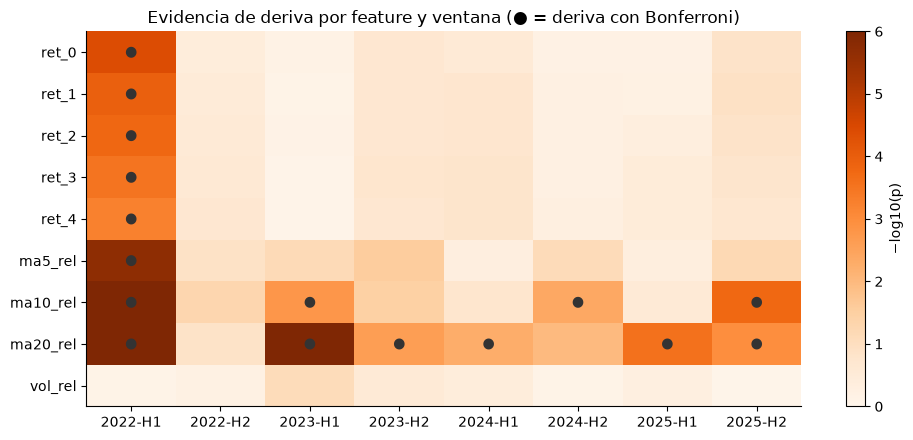

In [6]:
dd = pd.read_csv("results/drift_details.csv")
piv = dd[(dd.replica == "logreg") & (dd.group == "B")].pivot(index="feature", columns="window_id", values="p_value").loc[FEATS]
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(-np.log10(piv.clip(lower=1e-16)), cmap="Oranges", aspect="auto", vmin=0, vmax=6)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        p = piv.iat[i, j]; ax.text(j, i, "●" if p < alpha / K else "", ha="center", va="center", color="#333")
ax.set_xticks(range(piv.shape[1]), piv.columns); ax.set_yticks(range(piv.shape[0]), piv.index); ax.grid(False)
plt.colorbar(im, label="−log10(p)"); ax.set_title("Evidencia de deriva por feature y ventana (● = deriva con Bonferroni)")
plt.tight_layout()
piv.min().rename("min_p").to_frame().T

**Cómo leerlo:** filas = features, columnas = ventanas. Cuanto más oscuro, más evidencia de deriva; ● marca dónde se cruzó el umbral. Cada ventana se compara contra los datos de entrenamiento del modelo vigente de B.

**Qué concluimos:** Hay deriva en **7 de 8 ventanas**; solo 2022-H2 se salva (min p = 0,053). Fuera de 2022-H1, la deriva la provocan casi solo `ma20_rel` y `ma10_rel`, que dependen del régimen alcista o bajista. **Advertencia:** KS supone días independientes, pero las medias móviles comparten 19 de 20 días entre filas vecinas. Eso infla la evidencia y hace que el test salte de más. En la práctica, B quedó convertido en C.

## 4. Umbral de desempeño por bootstrap

¿Cuánto puede variar el F1 solo por azar? El F1 no tiene una fórmula simple de varianza ([25]), así que se estima remuestreando:

1. Se separan las **últimas 63 filas** del entrenamiento como hold-out temporal.
2. Se entrena con el resto y se predice el hold-out.
3. Se sortean **1000 veces 126 pares (real, predicho)** con reemplazo (126 = tamaño de una ventana) y se calcula el F1 de cada sorteo.
4. `F1_ref` = media de esos F1 y `σ` = su desviación estándar. B reentrena si `F1_ventana < F1_ref − 2σ`, que es el nivel de aviso de DDM (~95 %) usado en [6].

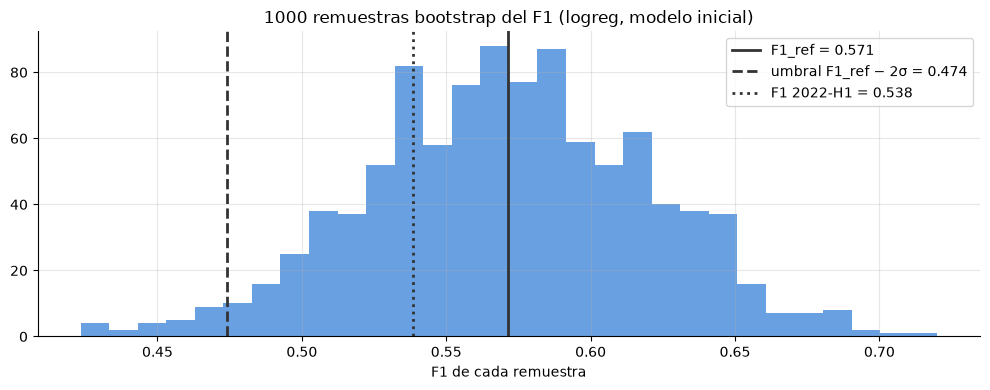

In [7]:
replica, params = "logreg", {"C": 0.1}
trig = cfg["f1_trigger"]; H, B, S = trig["holdout_rows"], trig["n_bootstrap"], trig["resample_size"]
head, hold = initial_df.iloc[:-H], initial_df.iloc[-H:]
m = fit_model(replica, params, cfg.seed, head[FEATS], head.y)
yt, yp = hold.y.to_numpy(), predict(m, hold[FEATS])
rng = np.random.default_rng(cfg.seed)
boot = np.array([f1_value(yt[i], yp[i]) for i in (rng.integers(0, H, size=S) for _ in range(B))])
boot = boot[~np.isnan(boot)]
f1_ref, sigma = boot.mean(), boot.std(ddof=1)
oficial = f1_reference_and_sigma(replica, params, cfg.seed, initial_df, FEATS, H, B, S)
assert np.isclose(f1_ref, oficial.f1_ref) and np.isclose(sigma, oficial.sigma)
m_full = fit_model(replica, params, cfg.seed, initial_df[FEATS], initial_df.y)
f1_w = f1_value(w.data.y, predict(m_full, w.data[FEATS]))
fig, ax = plt.subplots()
ax.hist(boot, bins=30, color=COLOR["A"], alpha=0.7)
for x, lab, ls in [(f1_ref, "F1_ref", "-"), (f1_ref - 2 * sigma, "umbral F1_ref − 2σ", "--"), (f1_w, f"F1 {w.window_id}", ":")]:
    ax.axvline(x, color="#333", ls=ls, label=f"{lab} = {x:.3f}")
ax.legend(); ax.set_xlabel("F1 de cada remuestra"); ax.set_title(f"1000 remuestras bootstrap del F1 ({replica}, modelo inicial)"); plt.tight_layout()

**Cómo leerlo:** el histograma muestra los 1000 F1 obtenidos al remuestrear. La línea punteada es el umbral de alarma y la de puntos el F1 real de 2022-H1.

**Qué concluimos:** El F1 de 2022-H1 (0,538) queda **por encima** del umbral (0,474): no hay caída anormal. La alarma de desempeño no se activa en esta ventana; la que se activó fue la de deriva.

## 5. El umbral de F1 en todas las ventanas

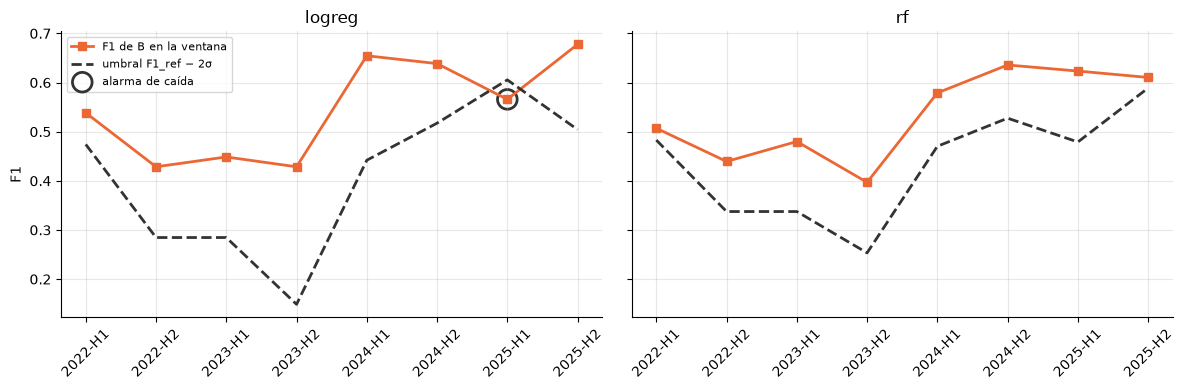

In [8]:
wm = pd.read_csv("results/window_metrics.csv"); mv = pd.read_csv("results/model_versions.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, r in zip(axes, cfg.replicas):
    b = wm[(wm.replica == r) & (wm.group == "B")].copy()
    m = mv[(mv.replica == r) & (mv.group == "B")].set_index("version")
    b["umbral"] = [m.loc[v, "f1_ref"] - 2 * m.loc[v, "sigma"] for v in b.version]
    ax.plot(b.window_id, b.f1, marker=MARKER["B"], color=COLOR["B"], label="F1 de B en la ventana")
    ax.plot(b.window_id, b.umbral, ls="--", color="#333", label="umbral F1_ref − 2σ")
    caida = b.f1 < b.umbral
    ax.scatter(b.window_id[caida], b.f1[caida], s=200, facecolors="none", edgecolors="#333", lw=2, label="alarma de caída")
    ax.set_title(r); ax.tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8); axes[0].set_ylabel("F1"); plt.tight_layout()

**Cómo leerlo:** la línea naranja es el F1 real de B y la punteada su umbral, que cambia con cada versión del modelo. Hay alarma cuando el F1 cae por debajo del umbral (círculo).

**Qué concluimos:** La alarma de desempeño se activó **una sola vez** (LR en 2025-H1: 0,566 < 0,605). En 2022–2023 los modelos entrenados con el año bajista tienen `F1_ref` muy bajo (≈ 0,27), así que el umbral cae a ≈ 0,15 y es inalcanzable. En este experimento, el disparador que manda es el de deriva.

## 6. La política combinada
Lo **único** que difiere entre los grupos es esta función:

In [9]:
pol = make_policies(cfg["f1_trigger"]["k_sigma"])
for g in "ABC":
    print(g, "→", pol[g].should_retrain(f1_w, dr, oficial) or "no reentrena")

A → no reentrena
B → deriva
C → periodico
